# Домашняя работа 3.2. Хаос в пищевой цепи
## Зелёный уровень

Рассматривается безразмерная модель Hastings–Powell: $x$ — жертва,
$y$ — хищник, $z$ — суперхищник.

$$
\dot x=x(1-x)-f_1(x)y,
$$

$$
\dot y=f_1(x)y-f_2(y)z-d_1y,\qquad
\dot z=f_2(y)z-d_2z,
$$

$$
f_i(u)=\frac{a_i u}{1+b_i u}.
$$

Параметры: $a_1=5$, $a_2=0.1$, $b_1=3$, $b_2=2$,
$d_1=0.4$, $d_2=0.01$. Начальное состояние $(0.5,0.1,0.1)$.
Время и популяции безразмерны.


## 1. Численное решение и проверка неотрицательности

Используется метод Рунге–Кутты четвёртого порядка (RK4) с постоянным шагом.
Расчёт на $0\leq t\leq10000$ повторяется при $h=0.1$, $0.05$ и $0.025$.

В точной модели каждая производная содержит множитель соответствующей популяции,
поэтому положительное решение не пересекает координатные плоскости.
RK4 сам по себе не гарантирует сохранения знака при произвольном шаге.
В коде проверяются все узлы решения; отрицательные значения не заменяются нулями.
Если проверка не проходит, расчёт следует повторить с меньшим шагом.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25})

a1, a2, b1, b2, d1, d2 = 5.0, 0.1, 3.0, 2.0, 0.4, 0.01
initial = np.array([0.5, 0.1, 0.1])
steps = [0.1, 0.05, 0.025]


def rhs(state):
    x, y, z = state
    f1 = a1 * x / (1 + b1 * x)
    f2 = a2 * y / (1 + b2 * y)
    return np.array([x * (1 - x) - f1 * y,
                     f1 * y - f2 * z - d1 * y, f2 * z - d2 * z])


def rk4_step(state, h):
    k1 = rhs(state)
    k2 = rhs(state + h * k1 / 2)
    k3 = rhs(state + h * k2 / 2)
    k4 = rhs(state + h * k3)
    return state + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6


def solve(h, end=10000):
    n = round(end / h)
    t = np.arange(n + 1) * h
    states = np.empty((n + 1, 3))
    states[0] = initial
    for i in range(n):
        states[i + 1] = rk4_step(states[i], h)
    if not np.all(np.isfinite(states)):
        raise ValueError("Решение содержит NaN или бесконечность: проверьте шаг.")
    if np.any(states < 0):
        i, j = np.argwhere(states < 0)[0]
        raise ValueError(f"Отрицательная популяция {j} при t={t[i]}. Уменьшите шаг.")
    return t, states


runs = {h: solve(h) for h in steps}
print("h        min x         min y         min z")
for h, (time, values) in runs.items():
    print(f"{h:<8g}" + "  ".join(f"{v:.8f}" for v in values.min(axis=0)))
t, states = runs[0.025]

h        min x         min y         min z
0.1     0.00046603  0.01196153  0.09996888
0.05    0.00046595  0.01196072  0.09996863
0.025   0.00046589  0.01196066  0.09996860


## 2. Временные ряды

Первые 5000 единиц времени отделены от последующего режима.
Для фазового портрета используются только точки с $t\geq5000$.
Дополнительно показан участок $5000\leq t\leq6500$, как на рисунках 2A–C статьи,
чтобы различать отдельные колебания. На графиках отображается каждая восьмая точка;
само интегрирование и проверка знака выполнены на полной сетке.

Число крупных максимумов z после t=5000: 38
Интервалы между ними: 115.375–137.950


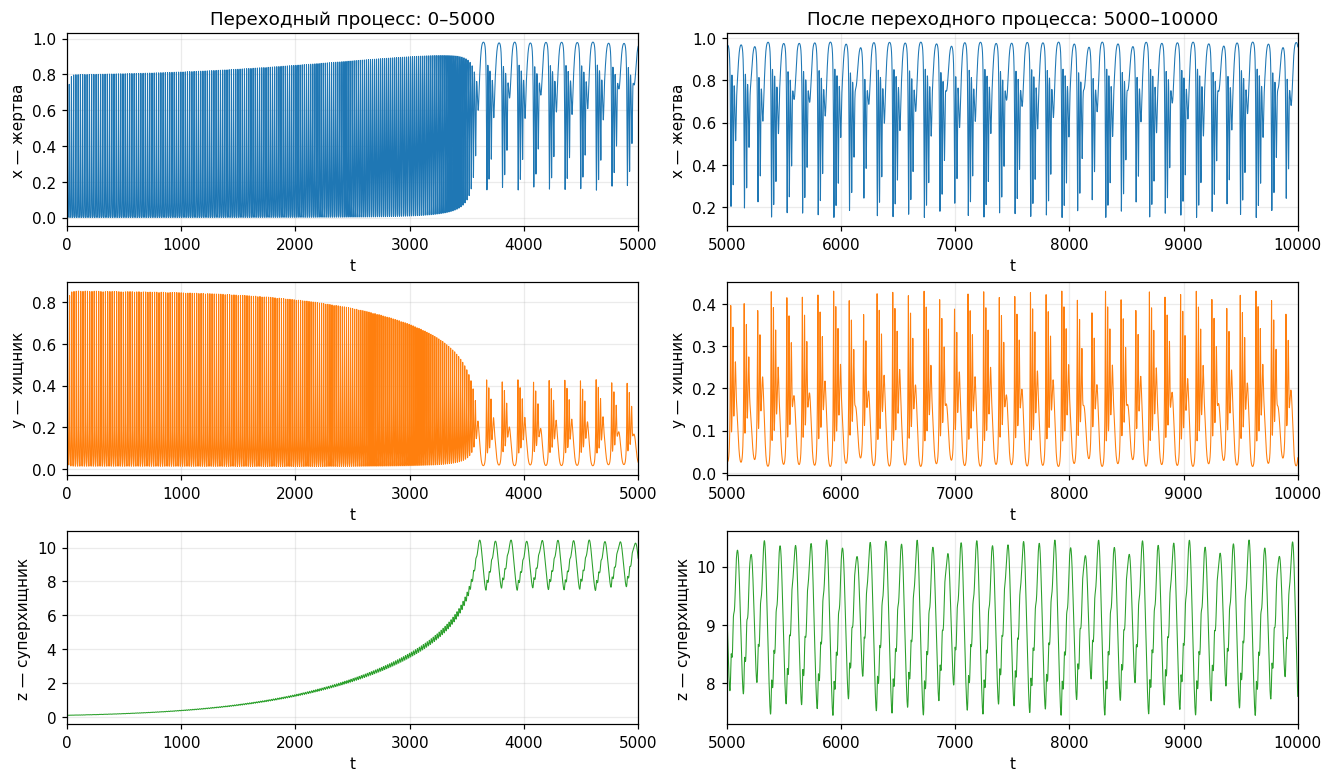

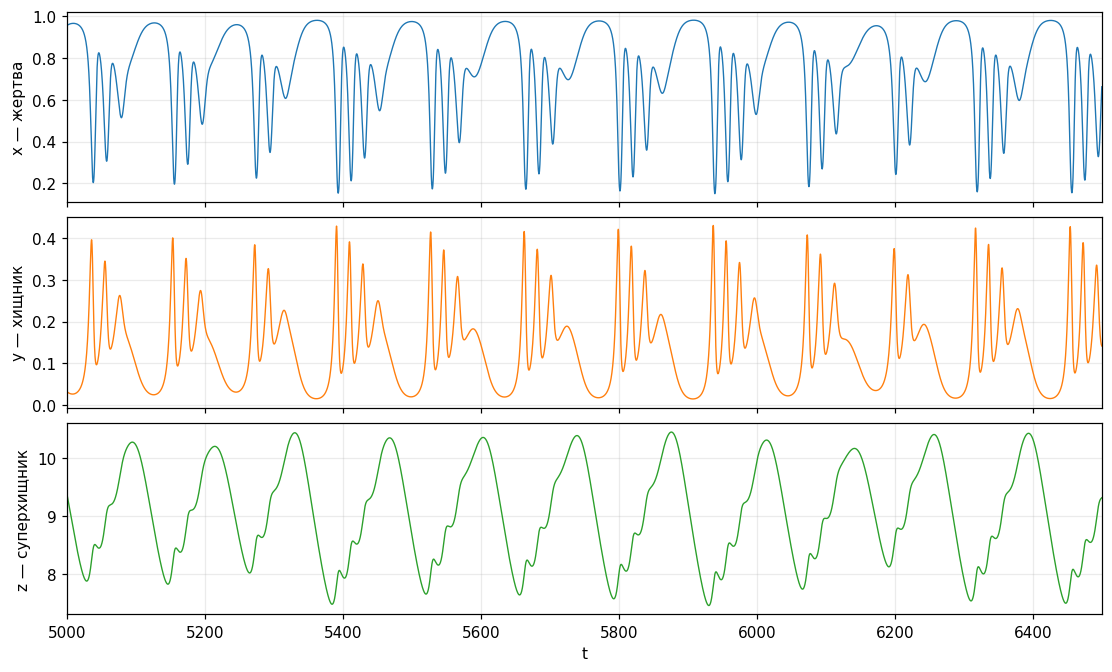

In [2]:
names = ["x — жертва", "y — хищник", "z — суперхищник"]
colors = ["tab:blue", "tab:orange", "tab:green"]
tp, sp = t[::8], states[::8]
fig, axes = plt.subplots(3, 2, figsize=(12, 7), layout="constrained")
for j, (name, color) in enumerate(zip(names, colors)):
    for col, (left, right) in enumerate([(0, 5000), (5000, 10000)]):
        mask = (tp >= left) & (tp <= right)
        axes[j, col].plot(tp[mask], sp[mask, j], color=color, linewidth=0.7)
        axes[j, col].set(xlabel="t", ylabel=name, xlim=(left, right))
axes[0, 0].set_title("Переходный процесс: 0–5000")
axes[0, 1].set_title("После переходного процесса: 5000–10000")
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True, layout="constrained")
mask = (tp >= 5000) & (tp <= 6500)
for j, ax in enumerate(axes):
    ax.plot(tp[mask], sp[mask, j], color=colors[j], linewidth=0.9)
    ax.set(ylabel=names[j], xlim=(5000, 6500))
axes[-1].set_xlabel("t")
plt.show()

z = states[:, 2]
peaks = np.flatnonzero((z[1:-1] > z[:-2]) & (z[1:-1] > z[2:])) + 1
peaks = peaks[(t[peaks] >= 5000) & (z[peaks] > 10)]
intervals = np.diff(t[peaks])
print(f"Число крупных максимумов z после t=5000: {len(peaks)}")
print(f"Интервалы между ними: {intervals.min():.3f}–{intervals.max():.3f}")

## 3. Фазовый портрет и сравнение со статьёй

Построены проекции на плоскости $(x,y)$, $(x,z)$ и $(y,z)$ для двух мелких шагов.
Трёхмерный рисунок позволяет сопоставить общую форму с рисунком 2D статьи.
Сравнивается форма множества траекторий, а не положение точек в один и тот же момент времени.

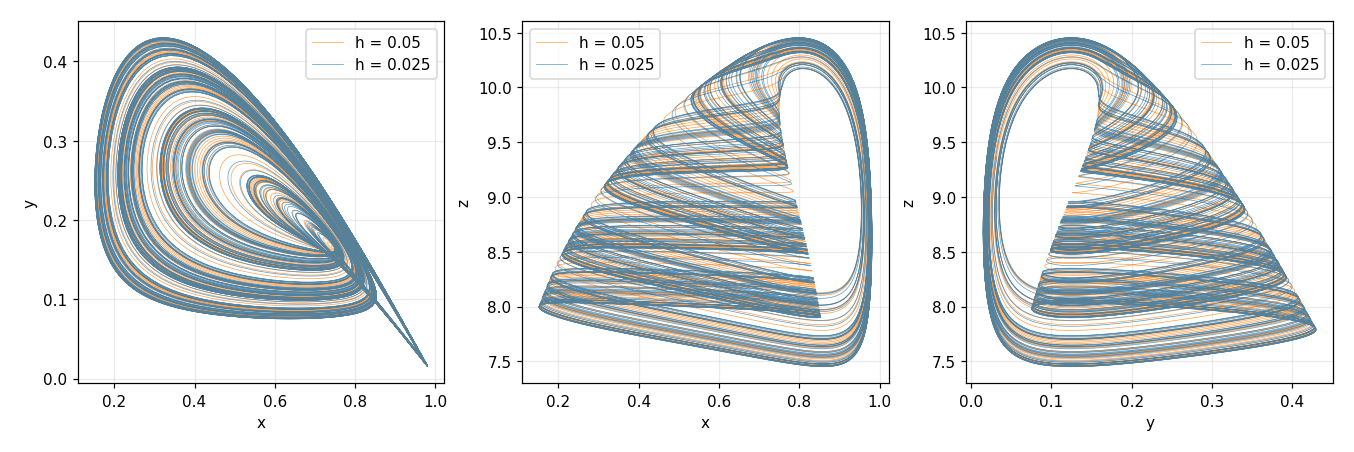

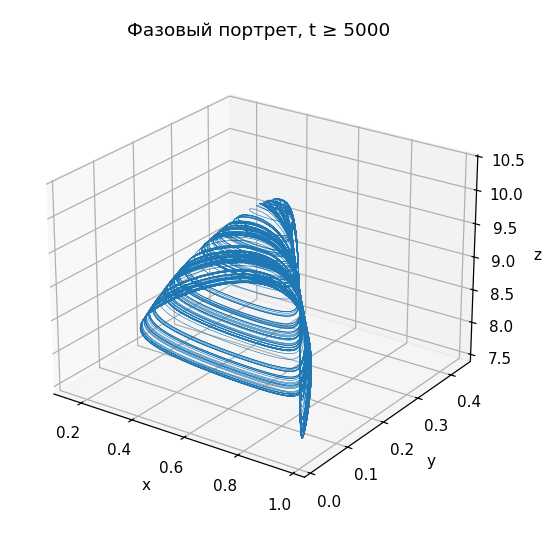

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for h, color in [(0.05, "tab:orange"), (0.025, "tab:blue")]:
    time, values = runs[h]
    phase = values[time >= 5000][::round(0.2 / h)]
    for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
        ax.plot(phase[:, i], phase[:, j], linewidth=0.45, alpha=0.75,
                color=color, label=f"h = {h}")
        ax.set(xlabel="xyz"[i], ylabel="xyz"[j])
        ax.legend()
plt.show()

phase = states[t >= 5000][::8]
fig = plt.figure(figsize=(7, 5))
fig.subplots_adjust(left=0.02, right=0.83, bottom=0.06, top=0.92)
ax = fig.add_subplot(111, projection="3d")
ax.plot(phase[:, 0], phase[:, 1], phase[:, 2], linewidth=0.4)
ax.set(xlabel="x", ylabel="y", zlabel="z", title="Фазовый портрет, t ≥ 5000")
ax.view_init(elev=24, azim=-55)
plt.show()

## 4. Проверка уменьшением шага

На начальном участке $0\leq t\leq100$ сравниваются решения в общих узлах.
Для метода четвёртого порядка при уменьшении шага вдвое ожидается снижение ошибки
примерно в 16 раз, пока она мала. На длинном интервале дополнительно сравниваются
диапазоны, средние значения популяций и форма фазового портрета.
Средние за конечный интервал могут различаться из-за сдвигов колебаний;
это не проверка поточечной точности до $t=10000$.

Отношение максимальных расхождений на 0–100: 17.52
h       вид      минимум    максимум    среднее (t ≥ 5000)
0.1     x          0.15112     0.98088     0.74389
0.1     y          0.01501     0.43010     0.13912
0.1     z          7.45122    10.45524     9.05476
0.05    x          0.15130     0.98084     0.74445
0.05    y          0.01505     0.42998     0.13871
0.05    z          7.45284    10.45437     9.04775
0.025   x          0.15114     0.98088     0.74595
0.025   y          0.01502     0.43009     0.13809
0.025   z          7.45145    10.45511     9.05459


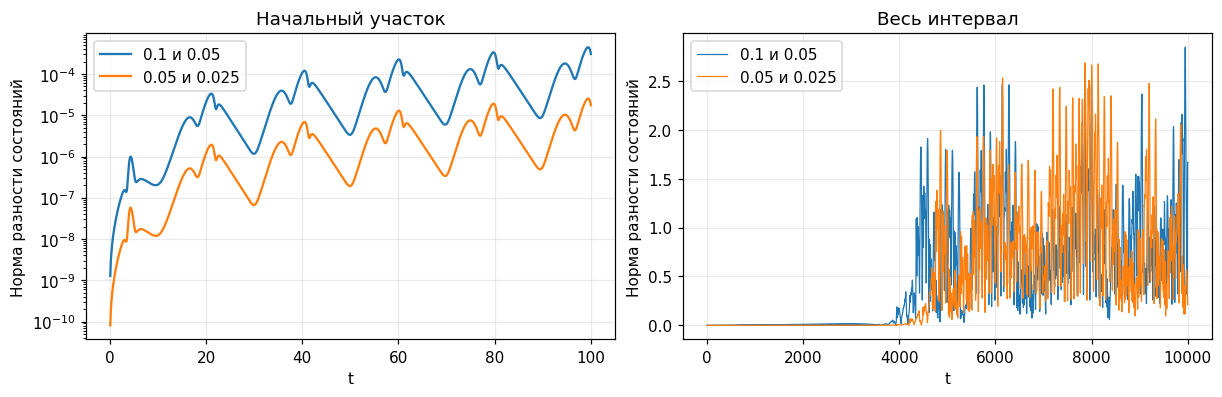

In [4]:
common = [runs[h][1][::round(0.1 / h)] for h in steps]
tc = runs[0.1][0]
early = tc <= 100
error1 = np.linalg.norm(common[0] - common[1], axis=1)
error2 = np.linalg.norm(common[1] - common[2], axis=1)
ratio = error1[early].max() / error2[early].max()
print(f"Отношение максимальных расхождений на 0–100: {ratio:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for error, label in [(error1, "0.1 и 0.05"), (error2, "0.05 и 0.025")]:
    axes[0].semilogy(tc[early][1:], error[early][1:], label=label)
    axes[1].plot(tc[::10], error[::10], label=label, linewidth=0.8)
axes[0].set(title="Начальный участок", xlabel="t", ylabel="Норма разности состояний")
axes[1].set(title="Весь интервал", xlabel="t", ylabel="Норма разности состояний")
for ax in axes:
    ax.legend()
plt.show()

print("h       вид      минимум    максимум    среднее (t ≥ 5000)")
for h, (time, values) in runs.items():
    tail = values[time >= 5000]
    for j, name in enumerate("xyz"):
        print(f"{h:<8g}{name:<8}{tail[:, j].min():10.5f}{tail[:, j].max():12.5f}"
              f"{tail[:, j].mean():12.5f}")

## Выводы

Отрицательных популяций на проверенных сетках нет. При $h=0.025$ минимумы за весь
интервал составили приблизительно 0.000466, 0.011961 и 0.099969 для $x,y,z$.
После $t=5000$ получены диапазоны $x\approx0.15$–$0.98$,
$y\approx0.015$–$0.43$, $z\approx7.45$–$10.46$.
Они согласуются с масштабами рисунка 2 статьи. В фазовом пространстве видны
многочисленные близкие витки и узкая соединяющая их часть, как на рисунке 2D;
траектория не сводится к одной замкнутой петле.

Амплитуды всплесков и число небольших колебаний между ними меняются.
Интервалы между крупными максимумами $z>10$ составили 115.375–137.950.
Эта нерегулярность сохраняется после удаления переходного процесса и при уменьшении шага.
На начальном участке отношение расхождений при двух последовательных уточнениях
сетки равно 17.52, что близко к ожидаемому для RK4 значению 16.

Нерегулярный временной ряд сам по себе не доказывает хаос: похожую картину могут
дать длительный переходный процесс, квазипериодическое движение или численная ошибка.
Проверки здесь подтверждают устойчивость наблюдаемой формы колебаний к шагу,
но для количественного установления хаоса нужен, например, положительный старший
показатель Ляпунова с проверкой его сходимости. В этой работе он не вычислялся.